# TinyStories — Easy PyTorch LSTM (Kaggle)

**Goal:** Predict the next word from the last **8 tokens** of a sentence.

This beginner project has **10 steps**. Train it once on Kaggle, save the model, and then run `app.py` with Streamlit.

**Before running:** In Kaggle Notebook settings, select **GPU** and turn **Internet ON**. Internet is needed to download TinyStories.

**Example:** `Once upon a time there was a little` → the model may guess `girl` or `boy`.

The model won't be perfect: different next words can all be sensible.

## 1. Install the tokenizer and dataset libraries
Kaggle already provides PyTorch. The extra packages help us download stories and tokenize words.

In [1]:
%pip -q install datasets tokenizers

Note: you may need to restart the kernel to use updated packages.


## 2. Imports and settings

You can change the four important values below: `TRAIN_STORIES`, `VAL_STORIES`, `VOCAB_SIZE`, and `SEQ_LEN`.

**Recommended first run:** 50,000 training stories and 5,000 validation stories. When it works, try 100,000 or 300,000 training stories. Bigger experiments take longer on free GPUs.

In [2]:
import json
from pathlib import Path
from itertools import islice

import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
from datasets import load_dataset
from tokenizers import Tokenizer, models, normalizers, pre_tokenizers, trainers

# Dataset and preprocessing settings
TRAIN_STORIES = 100_000     # later try 100_000 or 300_000
VAL_STORIES = 10_000
VOCAB_SIZE = 20_000       # maximum number of tokens
SEQ_LEN = 8              # use 8 previous tokens to predict the next
STRIDE = 8               # move the window 8 tokens each time
SAMPLES_PER_STORY = 8    # keep the notebook manageable

# Training settings
BATCH_SIZE = 128
EPOCHS = 20
PATIENCE = 3
LEARNING_RATE = 0.001

# Model settings: same values are used later in Streamlit
EMBED_DIM = 64
HIDDEN_SIZE = 256
NUM_LAYERS = 2
DROPOUT = 0.2

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SAVE_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
print("Device:", DEVICE)
print("Save directory:", SAVE_DIR)

Device: cuda
Save directory: /kaggle/working


## 3. Load TinyStories

The dataset has **separate training and validation splits**. We never train on validation stories.

`islice` lets us take only the number of stories we want instead of downloading the whole dataset into memory.

In [3]:
def get_stories(split, number):
    data = load_dataset("roneneldan/TinyStories", split=split, streaming=True)
    return [row["text"] for row in islice(data, number)]

train_stories = get_stories("train", TRAIN_STORIES)
val_stories = get_stories("validation", VAL_STORIES)

print("Training stories:", len(train_stories))
print("Validation stories:", len(val_stories))
print("Example:", train_stories[0][:250])

README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

Training stories: 100000
Validation stories: 10000
Example: One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, 


## 4. Tokenize text (prebuilt library)

The tokenizer handles lowercase text, splits it into tokens, and assigns a numeric ID to each token.

For example, `Once upon a time` becomes a list of numeric IDs. **We train the tokenizer using training stories only**, then save it for Streamlit.

In [4]:
tokenizer = Tokenizer(models.WordLevel(unk_token="[UNK]"))
tokenizer.normalizer = normalizers.Lowercase()
tokenizer.pre_tokenizer = pre_tokenizers.Whitespace()

trainer = trainers.WordLevelTrainer(
    vocab_size=VOCAB_SIZE,
    min_frequency=2,
    special_tokens=["[PAD]", "[UNK]", "[EOS]"]
)

tokenizer.train_from_iterator(train_stories, trainer=trainer)
tokenizer.save(str(SAVE_DIR / "tokenizer.json"))

PAD_ID = tokenizer.token_to_id("[PAD]")
EOS_ID = tokenizer.token_to_id("[EOS]")
ACTUAL_VOCAB_SIZE = tokenizer.get_vocab_size()

print("Actual vocabulary size:", ACTUAL_VOCAB_SIZE)
print("Tokens:", tokenizer.encode("Once upon a time").tokens)
print("IDs:", tokenizer.encode("Once upon a time").ids)

Actual vocabulary size: 14173
Tokens: ['once', 'upon', 'a', 'time']
IDs: [47, 51, 8, 39]


## 5. Create X and y

`X` = previous 8 tokens; `y` = the next token. For example:

`[once, upon, a, time, there, was, a, little]` → `girl`

The function takes at most **4 training windows from each story** so it can run in a Kaggle free session. It never joins two stories together. `STRIDE=8` means the window moves 8 tokens.

In [5]:
def make_examples(stories):
    X, y = [], []

    for story in stories:
        ids = tokenizer.encode(story).ids + [EOS_ID]
        positions = list(range(0, len(ids) - SEQ_LEN, STRIDE))

        # Use a few windows spread across the story, rather than all windows.
        step = max(1, len(positions) // SAMPLES_PER_STORY)
        for start in positions[::step][:SAMPLES_PER_STORY]:
            X.append(ids[start:start + SEQ_LEN])
            y.append(ids[start + SEQ_LEN])

    return torch.tensor(X, dtype=torch.long), torch.tensor(y, dtype=torch.long)

X_train, y_train = make_examples(train_stories)
X_val, y_val = make_examples(val_stories)

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
validation_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False)

print("Training examples:", len(X_train))
print("Validation examples:", len(X_val))
print("Example X shape:", X_train[0].shape)
print("Target word:", tokenizer.id_to_token(y_train[0].item()))

# The stories are no longer needed after converting them to tensors.
del train_stories, val_stories

Training examples: 799833
Validation examples: 79987
Example X shape: torch.Size([8])
Target word: found


## 6. Create a simple LSTM

Three important layers:

1. `Embedding`: changes word IDs into vectors.
2. `LSTM`: learns the order of words.
3. `Linear`: gives one score for every possible next token.

This class is **exactly the same** as in `model.py` used by Streamlit.

In [10]:
import torch
import torch.nn as nn


class NextWordLSTM(nn.Module):
    """A small LSTM: word IDs -> embeddings -> LSTM -> next-word scores."""

    def __init__(self, vocab_size, embed_dim=64, hidden_size=128, num_layers=2, dropout=0.2, pad_id=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_id)
        self.lstm = nn.LSTM(embed_dim, hidden_size, num_layers=num_layers, dropout=dropout if num_layers > 1 else 0, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, vocab_size)

    def forward(self, x):
        x = self.embedding(x)     # (batch, sequence, embedding dimension)
        output, _ = self.lstm(x)
        last = output[:, -1, :]  # keep the last LSTM output
        last = self.dropout(last)
        return self.fc(last)     # one score for every token in the vocabulary

model = NextWordLSTM(
    vocab_size=ACTUAL_VOCAB_SIZE,
    embed_dim=EMBED_DIM,
    hidden_size=HIDDEN_SIZE,
    num_layers  = NUM_LAYERS,
    dropout=DROPOUT,
    pad_id=PAD_ID
).to(DEVICE)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
print(model)

NextWordLSTM(
  (embedding): Embedding(14173, 64, padding_idx=0)
  (lstm): LSTM(64, 256, num_layers=2, batch_first=True, dropout=0.2)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=256, out_features=14173, bias=True)
)


## 7. Train + validate + early stopping

Training uses `model.train()` and validation uses `model.eval()`. After every epoch, the model is tested on **unseen validation examples**.

We save the model with the **lowest validation loss**, then stop if validation does not improve for 3 epochs. The loss and accuracy numbers will be different on each run.

In [11]:
train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []
best_val_loss = float("inf")
wait = 0

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0
    train_correct = 0
    train_total = 0

    for inputs, targets in train_loader:
        inputs = inputs.to(DEVICE)
        targets = targets.to(DEVICE)

        predictions = model(inputs)
        loss = loss_fn(predictions, targets)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * targets.size(0)
        train_correct += (predictions.argmax(1) == targets).sum().item()
        train_total += targets.size(0)

    # Evaluate on separate validation stories
    model.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for inputs, targets in validation_loader:
            inputs = inputs.to(DEVICE)
            targets = targets.to(DEVICE)
            predictions = model(inputs)
            loss = loss_fn(predictions, targets)

            val_loss += loss.item() * targets.size(0)
            val_correct += (predictions.argmax(1) == targets).sum().item()
            val_total += targets.size(0)

    avg_train_loss = train_loss / train_total
    avg_val_loss = val_loss / val_total
    train_acc = 100 * train_correct / train_total
    val_acc = 100 * val_correct / val_total

    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {avg_train_loss:.3f} | Val Loss: {avg_val_loss:.3f} | "
          f"Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}%")

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        wait = 0
        torch.save(model.state_dict(), SAVE_DIR / "best_lstm.pth")
        print("  Best model saved!")
    else:
        wait += 1
        if wait >= PATIENCE:
            print("Early stopping")
            break

# Load the best weights, not the weights from the final epoch.
model.load_state_dict(torch.load(SAVE_DIR / "best_lstm.pth", map_location=DEVICE, weights_only=True))
model.eval()

Epoch 1/20 | Train Loss: 4.224 | Val Loss: 3.633 | Train Acc: 26.04% | Val Acc: 32.26%
  Best model saved!
Epoch 2/20 | Train Loss: 3.513 | Val Loss: 3.395 | Train Acc: 33.44% | Val Acc: 35.66%
  Best model saved!
Epoch 3/20 | Train Loss: 3.296 | Val Loss: 3.299 | Train Acc: 35.64% | Val Acc: 36.86%
  Best model saved!
Epoch 4/20 | Train Loss: 3.168 | Val Loss: 3.249 | Train Acc: 36.82% | Val Acc: 37.54%
  Best model saved!
Epoch 5/20 | Train Loss: 3.079 | Val Loss: 3.222 | Train Acc: 37.66% | Val Acc: 38.10%
  Best model saved!
Epoch 6/20 | Train Loss: 3.010 | Val Loss: 3.209 | Train Acc: 38.26% | Val Acc: 38.33%
  Best model saved!
Epoch 7/20 | Train Loss: 2.954 | Val Loss: 3.206 | Train Acc: 38.84% | Val Acc: 38.71%
  Best model saved!
Epoch 8/20 | Train Loss: 2.907 | Val Loss: 3.200 | Train Acc: 39.26% | Val Acc: 38.87%
  Best model saved!
Epoch 9/20 | Train Loss: 2.864 | Val Loss: 3.210 | Train Acc: 39.71% | Val Acc: 38.95%
Epoch 10/20 | Train Loss: 2.830 | Val Loss: 3.216 | Train

NextWordLSTM(
  (embedding): Embedding(14173, 64, padding_idx=0)
  (lstm): LSTM(64, 256, num_layers=2, batch_first=True, dropout=0.2)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=256, out_features=14173, bias=True)
)

## 8. Show Matplotlib graphs
Loss should generally decrease as the model learns. If validation loss increases while training loss decreases, you might be overfitting.

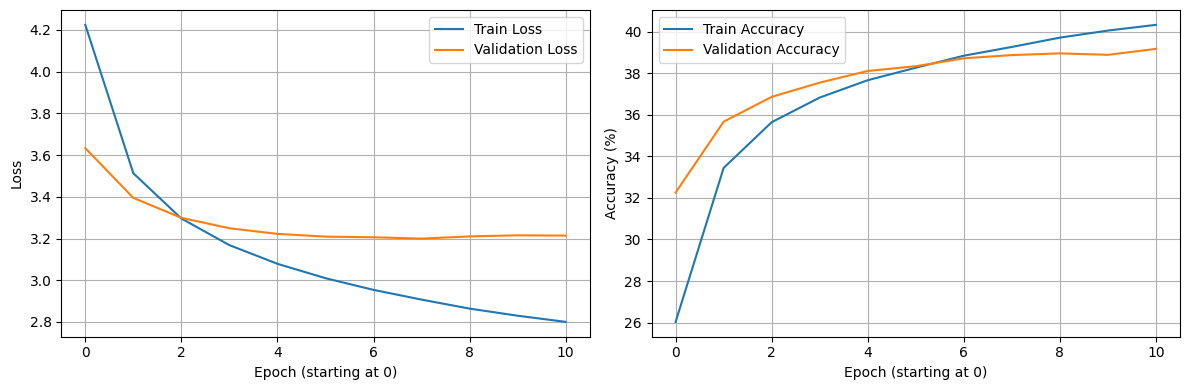

In [12]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch (starting at 0)")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label="Train Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch (starting at 0)")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig(SAVE_DIR / "training_graphs.png")
plt.show()

## 9. Save configuration for Streamlit

Our trained model needs **three files**: weights, tokenizer, and the architecture settings used in Kaggle. Streamlit loads exactly the same settings.

In [13]:
config = {
    "vocab_size": ACTUAL_VOCAB_SIZE,
    "embed_dim": EMBED_DIM,
    "hidden_size": HIDDEN_SIZE,
    "num_layers": NUM_LAYERS,
    "dropout": DROPOUT,
    "pad_id": PAD_ID,
    "seq_len": SEQ_LEN
}

with open(SAVE_DIR / "config.json", "w", encoding="utf-8") as file:
    json.dump(config, file, indent=2)

print("Saved:", SAVE_DIR / "best_lstm.pth")
print("Saved:", SAVE_DIR / "tokenizer.json")
print("Saved:", SAVE_DIR / "config.json")

Saved: /kaggle/working/best_lstm.pth
Saved: /kaggle/working/tokenizer.json
Saved: /kaggle/working/config.json


## 10. Test a prediction + download files

Test the trained model. Then download the ZIP and extract its three files into `model_files/` in your GitHub project.

In [14]:
def predict_next_word(sentence):
    ids = tokenizer.encode(sentence).ids
    ids = ([PAD_ID] * SEQ_LEN + ids)[-SEQ_LEN:]
    inputs = torch.tensor([ids], dtype=torch.long, device=DEVICE)

    with torch.no_grad():
        scores = model(inputs)[0]
        word_ids = [i for word, i in tokenizer.get_vocab().items() if word.isalpha()]
        best_index = scores[word_ids].argmax().item()

    return tokenizer.id_to_token(word_ids[best_index])

print("Next word:", predict_next_word("Once upon a time there was a little"))

# Create a ZIP for easier downloading from Kaggle Outputs.
import zipfile
with zipfile.ZipFile(SAVE_DIR / "trained_model_files.zip", "w") as archive:
    for name in ["best_lstm.pth", "tokenizer.json", "config.json"]:
        archive.write(SAVE_DIR / name, arcname=name)
print("Ready:", SAVE_DIR / "trained_model_files.zip")

Next word: girl
Ready: /kaggle/working/trained_model_files.zip


## After training

1. In Kaggle, use **Save Version** and verify the output files are available, or download `trained_model_files.zip`.
2. Extract `best_lstm.pth`, `tokenizer.json`, and `config.json` into the `model_files` folder supplied in the project ZIP.
3. Upload your project folder to GitHub, including these three model files.
4. On Streamlit Community Cloud, deploy `app.py` from your GitHub repository.

If your Kaggle session ends, you do not need to retrain to serve the model. Keep those three files safe.

## Step 1: Create the story generation function

In [20]:
import torch
import re

def generate_story(sentence, max_tokens=100):

    model.eval()

    # Step 1: Convert input sentence to token IDs
    tokens = tokenizer.encode(sentence).ids

    if len(tokens) == 0:
        return "Please enter a sentence."

    # Special token IDs
    unk_id = tokenizer.token_to_id("[UNK]")
    eos_id = tokenizer.token_to_id("[EOS]")

    # Step 2: Generate new tokens
    for i in range(max_tokens):

        # Use the last 8 tokens, with padding if needed
        input_ids = ([PAD_ID] * SEQ_LEN + tokens)[-SEQ_LEN:]

        # Convert input to tensor
        X = torch.tensor(
            [input_ids],
            dtype=torch.long,
            device=DEVICE
        )

        # Step 3: Predict next token
        with torch.no_grad():

            output = model(X)[0]

            # Avoid predicting padding or unknown tokens
            output[PAD_ID] = float("-inf")
            output[unk_id] = float("-inf")

            # Step 4: Top-K sampling
            top_values, top_indices = torch.topk(output, 10)

            probabilities = torch.softmax(
                top_values / 0.8,
                dim=0
            )

            selected = torch.multinomial(
                probabilities, 1
            )

            predicted_id = top_indices[selected].item()

        # Stop when EOS is predicted
        if predicted_id == eos_id:
            break

        # Add predicted token to the story
        tokens.append(predicted_id)

    # Step 5: Convert IDs back to text
    story = tokenizer.decode(
        tokens,
        skip_special_tokens=True
    )

    # Remove spaces before punctuation
    story = re.sub(r"\s+([.,!?;:])", r"\1", story)

    return story

## Step 2: Generate a TinyStory

In [24]:
story = generate_story(
    sentence="Once upon a time there was a little",
    max_tokens=100
)

print("Generated TinyStory:\n")
print(story)

Generated TinyStory:

once upon a time there was a little girl. she was very excited to go outside. she was so happy. she wanted to make a mess. she asked her mum for helping, but she kept trying. one day, the little girl was playing outside and she saw a big, scary dog. they looked and laughed and had a great picture. lily wanted to go and play in the park. one day, timmy ' s mom asked him to help him make a mess. timmy asked her mum for help. she gave her a big
